In [1]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    log_loss,
)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from scipy import stats as sstats
from catboost import CatBoostRegressor, CatBoostClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

RNG_SEED = 42
MIN_WORKING_AGE = 15
WEEKS_PER_MONTH = 365.25 / 7 / 12  # ~4.348


In [2]:
# --- toggles -----------------------------------------------------------
INCLUDE_EMPSTAB = True   # see design-decisions table above: circular under the zero-inclusive regime
INCLUDE_HRSWK = True  # team decision (Vanni's email) excludes hours for the female model;
                              # the audit branch's train-catboost_raw*.ipynb notebooks all keep it
                              # for female too. Toggle this to test how much of their higher
                              # reported R2 comes from that one feature, holding everything else
                              # (repeated eval, intensive-margin decomposition, wage formula, cap)
                              # fixed at our more rigorous setup.
ZERO_HANDLING = "drop_random"    # one of: "none", "drop_random", "lognormal_synthetic"
PREDICT_LOG_WAGE = False
INCLUDE_RIBASIM = False
WAGE_PERTURBATION = False
WAGE_PERTURBATION_SIGMA = 0.03
DROP_RANDOM_FRAC = 1.0    # only used when ZERO_HANDLING == "drop_random"
N_REPS = 100               # change this

MALE_OUTLIER_CAP = 5000
FEMALE_OUTLIER_CAP = 4000

DATA_FILENAME = "data_correlation.xlsx"

In [3]:
REPO_ROOT = Path.cwd().parent
LOCAL_DATA_ROOT = Path(os.environ.get("EGYPT_DATA_ROOT", REPO_ROOT / "ERF_Data" / "Data"))

_onedrive_home = Path("~").expanduser()

_egypt_candidates = [
    _onedrive_home / "OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt",
]

_erf_candidates = [
    _onedrive_home / "OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt_ERF_data",
]

egypt_root = next((p for p in _egypt_candidates if p.exists()), None)
erf_root = next((p for p in _erf_candidates if p.exists()), None)

if (LOCAL_DATA_ROOT / DATA_FILENAME).exists():
    DATA_ROOT = LOCAL_DATA_ROOT
    EXCEL_PATH = DATA_ROOT / DATA_FILENAME
    CROSSWALK_CSV = DATA_ROOT / "crosswalk" / "reg_governorate_crosswalk.csv"
    COMMAND_AREA_CROSSWALK_CSV = DATA_ROOT / "crosswalk" / "command_area_governorate_crosswalk.csv"
    print(f"data source: local ({DATA_ROOT})")
else:
    if egypt_root is None or erf_root is None:
        raise FileNotFoundError(
            "Could not find required OneDrive folders."
        )

    DATA_ROOT = egypt_root / "04_Data/2026_data"
    EXCEL_PATH = erf_root / DATA_FILENAME
    CROSSWALK_CSV = DATA_ROOT.parent / "cleaned_data/crosswalk" / "reg_governorate_crosswalk.csv"
    COMMAND_AREA_CROSSWALK_CSV = DATA_ROOT.parent / "cleaned_data/crosswalk" / "command_area_governorate_crosswalk.csv"
    # print(f"data source: OneDrive fallback ({_onedrive_root})")

LFS_DTA = DATA_ROOT / "Labor Force Survey, LFS 2022 - Egypt, Arab Rep., 2022" / "Egypt 2022-LFS IND-V1.dta"
HH_DTA = DATA_ROOT / "Labor Force Survey, LFS 2022 - Egypt, Arab Rep., 2022" / "Egypt 2022-LFS HH-V1.dta"
RESULT_DIR = DATA_ROOT.parent / "Result"
MASK_XLSX = RESULT_DIR / "correlation.xlsx"
POP_DENSITY_CSV = RESULT_DIR / "population_density_matrix.csv"

for p in [LFS_DTA, HH_DTA, CROSSWALK_CSV, COMMAND_AREA_CROSSWALK_CSV, MASK_XLSX, POP_DENSITY_CSV, EXCEL_PATH]:
    print(("OK  " if p.exists() else "MISSING "), p)


OK   /Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt/04_Data/2026_data/Labor Force Survey, LFS 2022 - Egypt, Arab Rep., 2022/Egypt 2022-LFS IND-V1.dta
OK   /Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt/04_Data/2026_data/Labor Force Survey, LFS 2022 - Egypt, Arab Rep., 2022/Egypt 2022-LFS HH-V1.dta
OK   /Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt/04_Data/cleaned_data/crosswalk/reg_governorate_crosswalk.csv
OK   /Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt/04_Data/cleaned_data/crosswalk/command_area_governorate_crosswalk.csv
OK   /Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt/04_Data/Result/correlation.xlsx
OK   /Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt/04_Data/Result/population_density_matrix.csv
OK   /Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt_ER

In [4]:
df = pd.read_stata(LFS_DTA, convert_categoricals=False)
hh = pd.read_stata(HH_DTA, convert_categoricals=False)
print("individual shape:", df.shape, " household shape:", hh.shape)

household_size = df.groupby("caseser").size()
n_employed_in_hh = df[df["emps"].notna()].groupby("caseser").size()
head_info = df[df["rel"] == 1].drop_duplicates("caseser").set_index("caseser")[["educ", "sex"]]
head_info.columns = ["head_educ", "head_sex"]

avg_hours_by_ind = df[df["hrswk"] > 0].groupby("ind")["hrswk"].mean()
head_hours = df[df["rel"] == 1].drop_duplicates("caseser").set_index("caseser")["hrswk"]
spouses_ind = df[df["rel"] == 2].sort_values(["caseser", "pnum"]).copy()
spouses_ind["spouse_order"] = spouses_ind.groupby("caseser").cumcount() + 1
spouse_hours = {n: spouses_ind[spouses_ind["spouse_order"] == n].set_index("caseser")["hrswk"] for n in [1, 2, 3]}

def convert_irregular(daily_wage, ind_code, real_hours):
    used_real = real_hours.notna() & (real_hours > 0)
    hours = real_hours.where(used_real, ind_code.map(avg_hours_by_ind))
    return daily_wage * (hours / 8) * 4

hh_wage = hh[hh["rururb"] == 0].copy()
hh_wage["head_hrswk"] = hh_wage["caseser"].map(head_hours)
hh_wage["irrwagehd"] = convert_irregular(hh_wage["irrgwaghd"].fillna(0), hh_wage["indhd"], hh_wage["head_hrswk"])
for n in [1, 2, 3]:
    hh_wage[f"sp_{n}_hrswk"] = hh_wage["caseser"].map(spouse_hours[n])
    hh_wage[f"irrwagesp_{n}"] = convert_irregular(
        hh_wage[f"irrgwagsp_{n}"].fillna(0), hh_wage[f"indsp_{n}"], hh_wage[f"sp_{n}_hrswk"]
    )
hh_wage["wagehd"] = hh_wage[["empinchd", "sempinchd", "totwaghd", "irrwagehd"]].sum(axis=1, skipna=True)
sp_cols = [f"{p}sp_{n}" for n in [1, 2, 3] for p in ["empinc", "sempinc", "totwag", "irrwage"]]
hh_wage["wagesp"] = hh_wage[sp_cols].sum(axis=1, skipna=True)
hh_wage["household_wage_total"] = hh_wage["wagehd"] + hh_wage["wagesp"]
hh_wage["wage_ratio"] = (hh_wage["wagesp"] / hh_wage["household_wage_total"]).fillna(0.5)
print("household_wage_total / wage_ratio computed for", len(hh_wage), "rural households")


individual shape: (299423, 106)  household shape: (76976, 116)
household_wage_total / wage_ratio computed for 45426 rural households


In [5]:
n_underage = (df["age"] < MIN_WORKING_AGE).sum()
working_age = df[df["age"] >= MIN_WORKING_AGE].copy()
rural = working_age[(working_age["rururb"] == 0) & (working_age["emps"].notna())].copy()
print(f"Dropped {n_underage} under age {MIN_WORKING_AGE}. Rural, working-age, employed: {len(rural)} rows "
      f"({(rural['sex']==1).sum()} male, {(rural['sex']==2).sum()} female)")

agri_pool = rural[rural["ind"] == 10].copy()
print(f"Rural + agriculture population: {len(agri_pool)} rows "
      f"({(agri_pool['sex']==1).sum()} male, {(agri_pool['sex']==2).sum()} female)")

_train_idx, _test_idx = train_test_split(
    agri_pool.index, test_size=0.2, random_state=RNG_SEED, stratify=agri_pool["sex"]
)
TEST_IDS = set(_test_idx)

test_pool = agri_pool.loc[list(TEST_IDS)].copy()
train_pool = agri_pool.loc[~agri_pool.index.isin(TEST_IDS)].copy()
survey_columns = train_pool.columns

assert TEST_IDS.isdisjoint(set(train_pool.index)), "test/train overlap -- must never happen"
print(f"\nTEST (rural + agriculture): {len(test_pool)} rows "
      f"({(test_pool['sex']==1).sum()} male, {(test_pool['sex']==2).sum()} female)")
print(f"TRAIN (rural + agriculture, test rows excluded): {len(train_pool)} rows "
      f"({(train_pool['sex']==1).sum()} male, {(train_pool['sex']==2).sum()} female)")


Dropped 100476 under age 15. Rural, working-age, employed: 46027 rows (39700 male, 6327 female)
Rural + agriculture population: 14043 rows (12019 male, 2024 female)

TEST (rural + agriculture): 2809 rows (2404 male, 405 female)
TRAIN (rural + agriculture, test rows excluded): 11234 rows (9615 male, 1619 female)


In [6]:
def attach_household_context(pool):
    pool = pool.copy()
    pool["household_size"] = pool["caseser"].map(household_size)
    pool["n_other_employed"] = pool["caseser"].map(n_employed_in_hh) - 1
    pool = pool.merge(head_info, on="caseser", how="left")
    pool = pool.merge(hh[["caseser", "malinlf", "feminlf", "occhd"]], on="caseser", how="left")
    pool = pool.merge(hh_wage[["caseser", "household_wage_total", "wage_ratio"]], on="caseser", how="left")
    return pool

def build_wage_target(pool):
    pool = pool.copy()
    valid_hours = pool["hrswk"].notna() & (pool["hrswk"] > 0)
    pool = pool[valid_hours].copy()

    # Same fills as the existing train-catboost*.ipynb notebooks (immigr: 3 = "No" migration,
    # the modal category; disabl: 0 = no disability). mart_d has no natural default -- dropped,
    # matching the existing notebooks' dropna(subset=['mart_d', 'yeduc']).
    if "immigr" in pool.columns:
        pool["immigr"] = pool["immigr"].fillna(3)
    if "disabl" in pool.columns:
        pool["disabl"] = pool["disabl"].fillna(0)
    if "mart_d" in pool.columns:
        n_before = len(pool)
        pool = pool.dropna(subset=["mart_d"])
        print(f"  dropped {n_before - len(pool)} rows missing mart_d")

    # Wage formula: matches train-catboost.ipynb, train-catboost-full-survey.ipynb, and
    # every train-catboost_raw*.ipynb variant exactly (verified directly against
    # train-catboost_raw_with_zeros_with_emps.ipynb, 2026-09-20) -- totwag + sempinc +
    # irrgwag*30. Earlier version of this notebook used an hrswk-based conversion for
    # irregular wages instead and dropped sempinc (self-employment income) entirely; that
    # was an unrequested deviation, not a considered improvement. Fixed here.
    pool["sempinc"] = pool["sempinc"].fillna(0)
    pool["irrgwag"] = pool["irrgwag"].fillna(0)
    pool["totwag"] = pool["totwag"].fillna(0)
    pool["totwag_all"] = pool["totwag"] + pool["sempinc"] + pool["irrgwag"] * 22

    # The fix: cap at <10,000 EGP, matching train-catboost_raw_with_zeros.ipynb's own
    # convention ("RAW wage, not log -- capped at <10000"). Diagnosed 2026-09-20: without
    # this, a handful of extreme outliers (up to 108,705 EGP/month in this population, vs a
    # test-set mean around 1,671 EGP) dominate the R2 calculation on raw-scale skewed wages.
    n_before = len(pool)
    pool = pool[pool["totwag_all"] < 10000].copy()
    print(f"  dropped {n_before - len(pool)} rows with totwag_all >= 10,000 EGP (outlier cap)")

    pool["is_paid"] = (pool["totwag_all"] > 0).astype(int)
    # Kept only for the lognormal_synthetic_augment experiment's internal sampling math
    # (drawing a synthetic wage from a log-normal assumption is inherently a log-space
    # operation) -- NOT used as the CatBoost fit target anymore, see fit_and_predict below.
    pool["log1p_wage"] = np.log1p(pool["totwag_all"])
    return pool

train_pool = build_wage_target(attach_household_context(train_pool))
test_pool = build_wage_target(attach_household_context(test_pool))
survey_columns = train_pool.columns

print(f"TRAIN: {len(train_pool)} rows, {train_pool['is_paid'].mean():.1%} paid overall "
      f"(male {train_pool.loc[train_pool['sex']==1,'is_paid'].mean():.1%}, "
      f"female {train_pool.loc[train_pool['sex']==2,'is_paid'].mean():.1%})")
print(f"TEST  (rural+agri only): {len(test_pool)} rows, {test_pool['is_paid'].mean():.1%} paid overall "
      f"(male {test_pool.loc[test_pool['sex']==1,'is_paid'].mean():.1%}, "
      f"female {test_pool.loc[test_pool['sex']==2,'is_paid'].mean():.1%})")


  dropped 232 rows missing mart_d
  dropped 19 rows with totwag_all >= 10,000 EGP (outlier cap)
  dropped 73 rows missing mart_d
  dropped 4 rows with totwag_all >= 10,000 EGP (outlier cap)
TRAIN: 10951 rows, 81.1% paid overall (male 91.1%, female 22.4%)
TEST  (rural+agri only): 2727 rows, 81.8% paid overall (male 91.7%, female 24.6%)


In [7]:
upper_egypt_govs = ['Aswan', 'Luxor', 'Qena', 'Suhag', 'Asyout', 'Menia', 'Beni- Suef', 'Fayoum', 'Cairo', 'Giza']

In [8]:
crosswalk = pd.read_csv(CROSSWALK_CSV)
distribution_df = pd.read_csv(POP_DENSITY_CSV, index_col="NAME1_")

def attach_governorate(pool):
    pool = pool.merge(crosswalk[["reg_code", "OBJECTID", "NAME1_"]], left_on="reg", right_on="reg_code", how="left")
    return pool

train_pool = attach_governorate(train_pool)
test_pool = attach_governorate(test_pool)

def assign_command_units(pool, seed):
    """Draw one random command unit per respondent from the (rural-population-weighted)
    governorate distribution. Rows landing on 'other' (outside every command area) are
    dropped -- matches assign-survey-data-to-command-units.ipynb."""
    rng = np.random.default_rng(seed)
    pool = pool.copy()
    pool["command_unit"] = None
    command_units = distribution_df.columns
    for gov, idx in pool.groupby("NAME1_").groups.items():
        if gov not in distribution_df.index:
            continue
        probs = distribution_df.loc[gov].drop("other")
        if probs.sum() == 0:
            continue
        probs = probs / probs.sum()
        
        pool.loc[idx, "command_unit"] = rng.choice(
            probs.index,
            size=len(idx),
            p=probs.values,
        )
        # probs = distribution_df.loc[gov].to_numpy()
        # pool.loc[idx, "command_unit"] = rng.choice(command_units, size=len(idx), p=probs)
    pool = pool[pool["command_unit"] != "other"]
    return pool[pool["command_unit"].notna()].copy()


In [9]:
excel_df = pd.read_excel(EXCEL_PATH, sheet_name="command_unit")
print(f"Loaded command_unit: {excel_df.shape[0]} areas, {excel_df.shape[1]} columns "
      f"(already scaled -- no rural-population normalization needed for this sheet)")


Loaded command_unit: 60 areas, 75 columns (already scaled -- no rural-population normalization needed for this sheet)


In [10]:
masking_df = pd.read_excel(MASK_XLSX, sheet_name="Sheet1")
base_cols = masking_df.loc[masking_df["correl"] == 1, "variable"].tolist()
# hrswk/hrswksc are handled separately below regardless of whether the mask file also lists
# them -- stripped here so they can never end up duplicated in the feature list.
base_cols = [c for c in base_cols if c not in ("emps", "hrswk", "hrswksc", "totwag")]
if not INCLUDE_EMPSTAB:
    base_cols = [c for c in base_cols if c != "empstab"]

# rel, attsch, occ aren't in the mask file (correl==0 there), so they were never in
# train-catboost_v2_agri.ipynb's feature set. Added here the same way as
# train-catboost_raw_with_zeros.ipynb: rel (relationship to household head) and attsch
# (school attendance) correlate with male zero-wage status at 0.27 and 0.26 -- real signal,
# not wage-derived. occ (occupation code) is a structural job characteristic, same category
# as empstab. Applied to both sexes, not gender-specific like hrswk.
EXTRA_FEATURES = [c for c in ["rel", "attsch", "occ"] if c in agri_pool.columns]
base_cols = base_cols + [c for c in EXTRA_FEATURES if c not in base_cols]

MALE_EXTRA = ["hrswk", "hrswksc"] if INCLUDE_HRSWK else []
FEMALE_EXTRA = ["hrswk", "hrswksc"] if INCLUDE_HRSWK else []

categorical_columns = masking_df[
    (masking_df["type"].isin(["binary", "categorical"])) & (masking_df["variable"].isin(base_cols))
]["variable"].tolist()
# rel, attsch, occ are nominal codes, not ordered numbers, and the mask file lists their type
# as "-" so the filter above never picks them up -- added explicitly.
categorical_columns = categorical_columns + [c for c in EXTRA_FEATURES if c not in categorical_columns]

print(f"Base feature list: {len(base_cols)} columns")
print(f"Categorical: {categorical_columns}")
print(f"INCLUDE_EMPSTAB={INCLUDE_EMPSTAB}  INCLUDE_HRSWK={INCLUDE_HRSWK}  ZERO_HANDLING={ZERO_HANDLING!r}")


Base feature list: 62 columns
Categorical: ['sex', 'mart_d', 'rel', 'immigr', 'disabl', 'lit', 'attsch', 'empstab', 'hlthins', 'socsec', 'occ']
INCLUDE_EMPSTAB=True  INCLUDE_HRSWK=True  ZERO_HANDLING='drop_random'


In [11]:
def drop_random_zeros(frame, frac, seed):
    rng = np.random.default_rng(seed)
    zero_idx = frame.index[frame["is_paid"] == 0]
    n_drop = int(len(zero_idx) * frac)
    drop_idx = rng.choice(zero_idx, size=n_drop, replace=False)
    kept = frame.drop(index=drop_idx)
    # print(f"  drop_random_zeros: removed {n_drop} of {len(zero_idx)} zero-wage rows "
    #       f"({frac:.0%}) -> {len(kept)} rows remain")
    return kept

def perturbate_wage(frame, seed, mu=0.0, sigma=WAGE_PERTURBATION_SIGMA):
    rng = np.random.default_rng(seed)
    wage = frame["totwag_all"]
    new_wage = wage * (1 + rng.normal(mu, sigma, size=wage.shape))
    frame["totwag_all"] = new_wage
    return frame


GEO_COLS = ["command_unit"] + [c for c in excel_df.columns if c != "area"]

def lognormal_synthetic_augment(frame, feature_cols, cat_cols, n_synthetic, k=5, seed=42):
    """Turn real zero-wage rows into hypothetical paid rows.

    - command_unit and every command-area covariate (GEO_COLS): copied AS-IS from the
      donor row's own real command unit. Never blended across command units -- a
      synthetic person still has to live somewhere real.
    - Other numeric individual-level columns: SMOGN-style k-NN interpolation between two
      REAL zero-wage donor rows, restricted to neighbors within the SAME command unit
      (same rule as above, applied to feature construction).
    - Categorical individual-level columns: copied from whichever of the two donors the
      interpolation weight favors (can't blend a category).
    - Wage: NOT interpolated between donors. Drawn from a log-normal fit conditioned on
      the donor's own command unit (median real log-wage of PAID people in that command
      unit + a residual drawn from the overall real residual spread), so the synthetic
      wage stays tied to real local wage levels instead of being pure noise independent
      of geography.
    """
    rng = np.random.default_rng(seed)
    paid = frame[frame["is_paid"] == 1]
    if len(paid) < 5:
        raise ValueError("too few real paid rows to fit a conditional log-normal")

    overall_resid_std = (paid["log1p_wage"] - paid.groupby("command_unit")["log1p_wage"].transform("median")).std()
    cu_median_log_wage = paid.groupby("command_unit")["log1p_wage"].median()
    global_median_log_wage = paid["log1p_wage"].median()

    donor_pool = frame[frame["is_paid"] == 0].reset_index(drop=True)
    geo_cols_present = [c for c in GEO_COLS if c in donor_pool.columns]
    num_cols = [c for c in feature_cols if c not in cat_cols and c not in geo_cols_present]

    from sklearn.neighbors import NearestNeighbors
    from sklearn.preprocessing import StandardScaler

    synth_rows = []
    for cu, group in donor_pool.groupby("command_unit"):
        if len(group) < 2:
            continue
        X_num = group[num_cols].fillna(np.nanmedian(group[num_cols])).to_numpy()
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X_num)
        nn = NearestNeighbors(n_neighbors=min(k + 1, len(group))).fit(X_scaled)
        _, neighbor_idx = nn.kneighbors(X_scaled)

        n_this_cu = max(1, round(n_synthetic * len(group) / len(donor_pool)))
        for _ in range(n_this_cu):
            i = rng.integers(0, len(group))
            j = rng.choice(neighbor_idx[i][1:]) if len(group) > 1 else i
            lam = rng.uniform(0, 1)
            row = group.iloc[i if lam < 0.5 else j].copy()  # geo + categorical columns come from this donor, untouched
            row[num_cols] = group.iloc[i][num_cols].to_numpy() + lam * (
                group.iloc[j][num_cols].to_numpy() - group.iloc[i][num_cols].to_numpy()
            )
            mu = cu_median_log_wage.get(cu, global_median_log_wage)
            synth_log_wage = mu + rng.normal(0, overall_resid_std)
            row["log1p_wage"] = max(synth_log_wage, 0.0)
            row["totwag_all"] = np.expm1(row["log1p_wage"])
            row["is_paid"] = 1
            synth_rows.append(row)

    synth_df = pd.DataFrame(synth_rows)
    print(f"  lognormal_synthetic_augment: generated {len(synth_df)} synthetic paid rows "
          f"\nfrom {donor_pool['command_unit'].nunique()} command units"
          f"\ntotal amount of orginal rows: {len(frame)} ({len(synth_df) / len(frame) * 100:.1f}% synthetic data)"
)
    return pd.concat([frame, synth_df], ignore_index=True)


In [12]:
def build_feature_frame(pool_with_geo, sex_code, excel_df=excel_df):
    cols = base_cols + (MALE_EXTRA if sex_code == 1 else FEMALE_EXTRA)
    frame = pool_with_geo[pool_with_geo["sex"] == sex_code].merge(
        excel_df, left_on="command_unit", right_on="area", how="inner"
    ).drop(columns=["area"])  # the join key duplicate -- command_unit already identifies the same thing
    keep = [c for c in cols if c in frame.columns] + ["log1p_wage", "totwag_all", "is_paid", "command_unit"]
    frame = frame.dropna(subset=["log1p_wage"])
    extra_info = frame[['pweight', 'command_unit']]
    frame = frame[keep]
    cats = [c for c in categorical_columns if c in frame.columns]
    # pandas's default `str` dtype (this environment: pandas 3.0) is NA-aware -- unlike the
    # pandas versions the older notebooks in this repo were written against, .astype(str) here
    # does NOT turn a real NaN into the literal text "nan" anymore, it leaves it as a genuine
    # missing value. CatBoost's cat_features cannot contain a raw NaN, so fillna first,
    # explicitly, rather than relying on astype(str) to paper over it.
    frame[cats] = frame[cats].fillna("missing").astype(str)
    return frame, cats, extra_info

def apply_zero_handling(frame, cat_cols, feature_cols, mode, seed):
    if mode == "none":
        return frame
    if mode == "drop_random":
        return drop_random_zeros(frame, DROP_RANDOM_FRAC, seed)
    if mode == "lognormal_synthetic":
        n_zero = (frame["is_paid"] == 0).sum()
        n_pos = (frame["is_paid"] == 1).sum()
        n_synthetic = max(0, n_zero - n_pos)  # bring toward parity, not necessarily exact 50/50
        return lognormal_synthetic_augment(frame, feature_cols, cat_cols, n_synthetic, seed=seed)
    raise ValueError(mode)

In [13]:
MODEL_DIR = REPO_ROOT / 'models/hp-tuned'
female_classifiers = sorted((MODEL_DIR / 'classifiers-with-hrs/female').glob('*.cbm'))
female_regressors = sorted((MODEL_DIR / 'regressors-with-hrs-22/female').glob('*.cbm'))
male_classifiers = sorted((MODEL_DIR / 'classifiers-with-hrs/male').glob('*.cbm'))
male_regressors = sorted((MODEL_DIR / 'regressors-with-hrs-22/male').glob('*.cbm'))

models = {
    "male": {'classifiers': male_classifiers, 'regressors': male_regressors},
    "female": {'classifiers': female_classifiers, 'regressors': female_regressors}
}

female_classifiers_nr = sorted((MODEL_DIR / 'no-ribasim/classifiers-with-hrs/female').glob('*.cbm'))
female_regressors_nr = sorted((MODEL_DIR / 'no-ribasim/regressors-with-hrs-22/female').glob('*.cbm'))
male_classifiers_nr = sorted((MODEL_DIR / 'no-ribasim/classifiers-with-hrs/male').glob('*.cbm'))
male_regressors_nr = sorted((MODEL_DIR / 'no-ribasim/regressors-with-hrs-22/male').glob('*.cbm'))

models_no_ribasim = {
    "male": {'classifiers': male_classifiers_nr, 'regressors': male_regressors_nr},
    "female": {'classifiers': female_classifiers_nr, 'regressors': female_regressors_nr}
}

In [14]:
train_geo = assign_command_units(train_pool, seed=0)
test_geo = assign_command_units(test_pool, seed=0)

train_test_values = {
    "male": {},
    "female": {}
}

extra_info = {
    "male": {},
    "female": {},
}

for sex_code, sex_label in [(1, "male"), (2, "female")]: 
    train_frame, _, extra_info_train = build_feature_frame(train_geo, sex_code=sex_code)
    test_frame, _, extra_info_test = build_feature_frame(test_geo, sex_code=sex_code)

    train_test_values[sex_label]["train_frame"] = train_frame
    train_test_values[sex_label]["test_frame"] = test_frame

    extra_info[sex_label]['weight'] = extra_info_test['pweight'].values
    extra_info[sex_label]['command_unit'] = extra_info_test['command_unit'].values
    
feature_cols = [c for c in train_frame.columns if c not in ("log1p_wage", "totwag_all", "is_paid", "command_unit")]
feature_cols_nr = [c for c in feature_cols if c in survey_columns]

X_train = train_frame[feature_cols]
y_train = train_frame["is_paid"]
X = test_frame[feature_cols]
y = test_frame["totwag_all"]

In [15]:
def make_prediction_raw(models, train_test_values, feature_cols=feature_cols, sex_label='female'):
    if sex_label == 'male':
        sex_code = 1
        outlier_cap = MALE_OUTLIER_CAP
    elif sex_label == 'female':
        sex_code = 2
        outlier_cap = FEMALE_OUTLIER_CAP
    else:
        sex_code = None
        outlier_cap = max(MALE_OUTLIER_CAP, FEMALE_OUTLIER_CAP)
        
    classifier_models = models[sex_label]['classifiers']
    regressor_models = models[sex_label]['regressors']
    cls_probs = []
    true_paid = []
    true_income = []

    for i, model_file in enumerate(classifier_models):
        model = CatBoostClassifier()
        model.load_model(model_file)

        train_geo = assign_command_units(train_pool, seed=42 + i)
        test_geo = assign_command_units(test_pool, seed=42 + i)
        
        train_frame, _, _ = build_feature_frame(train_geo, sex_code=sex_code)
        test_frame, _, _ = build_feature_frame(test_geo, sex_code=sex_code)

        train_frame = train_frame[train_frame['totwag_all'] < outlier_cap]
        test_frame = test_frame[test_frame['totwag_all'] < outlier_cap]
        
        X = test_frame[feature_cols]
        cls_probs.append(model.predict_proba(X)[:, 1])
        true_paid.append(test_frame["is_paid"])
        true_income.append(test_frame["totwag_all"])
    
    # cls_probs = np.array(cls_probs)
    
    # p_income = cls_probs.mean(axis=0)
    # has_income = p_income >= 0.5
    
    reg_preds = []
    
    for i, model_file in enumerate(regressor_models):
        model = CatBoostRegressor()
        model.load_model(model_file)

        train_geo = assign_command_units(train_pool, seed=42 + i)
        test_geo = assign_command_units(test_pool, seed=42 + i)
        
        train_frame, _, _ = build_feature_frame(train_geo, sex_code=sex_code)
        test_frame, _, _ = build_feature_frame(test_geo, sex_code=sex_code)

        train_frame = train_frame[train_frame['totwag_all'] < outlier_cap]
        test_frame = test_frame[test_frame['totwag_all'] < outlier_cap]
        
        X = test_frame[feature_cols]
        
        reg_preds.append(model.predict(X))

    cls_preds = np.array(cls_probs)
    reg_preds = np.array(reg_preds)
    true_paid = np.array(true_paid)
    true_income = np.array(true_income)

    return cls_probs, reg_preds, true_paid, true_income

def make_prediction(models, train_test_values, feature_cols=feature_cols, sex_label='female', cls_threshold=0.5, excel_df=excel_df):
    if sex_label == 'male':
        sex_code = 1
        outlier_cap = MALE_OUTLIER_CAP
    elif sex_label == 'female':
        sex_code = 2
        outlier_cap = FEMALE_OUTLIER_CAP
    else:
        sex_code = None
        outlier_cap = max(MALE_OUTLIER_CAP, FEMALE_OUTLIER_CAP)
        
    classifier_models = models[sex_label]['classifiers']
    regressor_models = models[sex_label]['regressors']
    cls_probs = []
    true_paid = []
    true_income = []

    for i, model_file in enumerate(classifier_models):
        model = CatBoostClassifier()
        model.load_model(model_file)

        # train_geo = assign_command_units(train_pool[train_pool['NAME1_'].isin(upper_egypt_govs)], seed=42 + i)
        # test_geo = assign_command_units(test_pool[test_pool['NAME1_'].isin(upper_egypt_govs)], seed=42 + i)

        train_geo = assign_command_units(train_pool, seed=42 + i)
        test_geo = assign_command_units(test_pool, seed=42 + i)
        
        train_frame, _, _ = build_feature_frame(train_geo, sex_code=sex_code, excel_df=excel_df)
        test_frame, _, _ = build_feature_frame(test_geo, sex_code=sex_code, excel_df=excel_df)

        train_frame = train_frame[train_frame['totwag_all'] < outlier_cap]
        test_frame = test_frame[test_frame['totwag_all'] < outlier_cap]
        
        X = test_frame[feature_cols]
        # print(model.predict_proba(X)[:, 1].shape)
        cls_probs.append(model.predict_proba(X)[:, 1])
        true_paid.append(test_frame["is_paid"])
        true_income.append(test_frame["totwag_all"])
    
    reg_preds = []
    
    for i, model_file in enumerate(regressor_models):
        model = CatBoostRegressor()
        model.load_model(model_file)

        # train_geo = assign_command_units(train_pool[train_pool['NAME1_'].isin(upper_egypt_govs)], seed=42 + i)
        # test_geo = assign_command_units(test_pool[test_pool['NAME1_'].isin(upper_egypt_govs)], seed=42 + i)

        train_geo = assign_command_units(train_pool, seed=42 + i)
        test_geo = assign_command_units(test_pool, seed=42 + i)
        
        train_frame, _, extra_info_train = build_feature_frame(train_geo, sex_code=sex_code, excel_df=excel_df)
        test_frame, _, extra_info_test = build_feature_frame(test_geo, sex_code=sex_code, excel_df=excel_df)

        extra_info[sex_label]['weight'] = extra_info_test[test_frame['totwag_all'] < outlier_cap]['pweight'].values
        extra_info[sex_label]['command_unit'] = extra_info_test[test_frame['totwag_all'] < outlier_cap]['command_unit'].values

        train_frame = train_frame[train_frame['totwag_all'] < outlier_cap]
        test_frame = test_frame[test_frame['totwag_all'] < outlier_cap]
        
        X = test_frame[feature_cols]
        
        reg_pred = model.predict(X)
        reg_pred = reg_pred * cls_probs[i]
        # reg_pred[cls_probs[i] < cls_threshold] = 0
        reg_preds.append(reg_pred)

    has_income = np.mean(np.array(cls_probs), axis=0)
    has_income = np.where(has_income < cls_threshold, 0, 1)
    # income_pred = np.concatenate(reg_preds)
    final_income = np.median(reg_preds, axis=0)
    # final_income = np.concatenate(reg_preds)

    true_paid = np.median(np.array(true_paid), axis=0)
    true_income = np.median(np.array(true_income), axis=0)

    return has_income, final_income, true_paid, true_income

In [16]:
cls_preds, reg_preds, _, _ = make_prediction_raw(models, train_test_values, feature_cols=feature_cols, sex_label='female')

In [17]:
cls_preds, reg_preds, true_paids, true_incomes = make_prediction_raw(models, train_test_values, feature_cols=feature_cols, sex_label='female')

r2_scores_female = []
for i in range(len(cls_preds)):
    # test_geo = assign_command_units(test_pool, seed=42 + i)
    # test_frame, _, _ = build_feature_frame(test_geo, sex_code=2)

    # true_paid_female = test_frame["is_paid"]
    # true_income_female = test_frame["totwag_all"]
    y_true = true_incomes[i]
    
    cls_pred = cls_preds[i]
    reg_pred = reg_preds[i]

    # paid_pred = cls_pred >= 0.5
    reg_pred[cls_pred < 0.33] = 0
    r2 = r2_score(y_true, reg_pred)
    r2_scores_female.append(r2)

cls_preds, reg_preds, true_paids, true_incomes = make_prediction_raw(models, train_test_values, feature_cols=feature_cols, sex_label='male')

r2_scores_male = []
y_trues_male = []
cls_preds_male = []
reg_preds_male = []
for i in range(len(cls_preds)):
    # test_geo = assign_command_units(test_pool, seed=42 + i)
    # test_frame, _, _ = build_feature_frame(test_geo, sex_code=1)

    # true_paid_male = test_frame["is_paid"]
    # true_income_male = test_frame["totwag_all"]
    # y_true = true_income_male
    y_true = true_incomes[i]
    y_trues_male.append(y_true)
    
    cls_pred = cls_preds[i]
    reg_pred = reg_preds[i]
    cls_preds_male.append(cls_pred)
    reg_preds_male.append(reg_pred)
    reg_pred = reg_pred * cls_pred

    # paid_pred = cls_pred >= 0.5
    # reg_pred[cls_pred < 0.5] = 0
    # reg_pred[true_paid_male == 0] = 0
    # y_true = y_true[reg_pred > 0]
    # reg_pred = reg_pred[reg_pred > 0]
    r2 = r2_score(y_true, reg_pred)
    r2_scores_male.append(r2)

r2_summary = pd.DataFrame({
    "metric": ["p5", "p50", "p95", "mean", "std", "min", "max"],
    "r2_female": [
        np.percentile(r2_scores_female, 5),
        np.percentile(r2_scores_female, 50),
        np.percentile(r2_scores_female, 95),
        np.mean(r2_scores_female),
        np.std(r2_scores_female),
        np.min(r2_scores_female),
        np.max(r2_scores_female),
    ],
    "r2_male": [
        np.percentile(r2_scores_male, 5),
        np.percentile(r2_scores_male, 50),
        np.percentile(r2_scores_male, 95),
        np.mean(r2_scores_male),
        np.std(r2_scores_male),
        np.min(r2_scores_male),
        np.max(r2_scores_male),
    ]
})

# r2_summary.to_csv('r2_summary_ribasim_with_hrs.csv')

In [17]:
pd.DataFrame({
    "truth": y_true.values,
    "prediction": reg_pred
}).to_csv('prediction_values_male.csv')

In [18]:
r2_summary

,metric,r2_female,r2_male
0,p5,0.500006,0.327030
1,p50,0.557924,0.371243
2,p95,0.599460,0.386850
3,mean,0.554979,0.365177
4,std,0.035417,0.018913
5,min,0.426524,0.314372
6,max,0.624019,0.396213


In [19]:
cls_preds, reg_preds = make_prediction_raw(models_no_ribasim, train_test_values, feature_cols=feature_cols_nr, sex_label='female')

r2_scores_female = []
for i in range(len(cls_preds)):
    test_geo = assign_command_units(test_pool, seed=42 + i)
    test_frame, _ = build_feature_frame(test_geo, sex_code=2)

    true_paid_female = test_frame["is_paid"]
    true_income_female = test_frame["totwag_all"]
    y_true = true_income_female
    
    cls_pred = cls_preds[i]
    reg_pred = reg_preds[i]

    # paid_pred = cls_pred >= 0.5
    reg_pred[cls_pred < 0.33] = 0
    r2 = r2_score(y_true, reg_pred)
    r2_scores_female.append(r2)

cls_preds, reg_preds = make_prediction_raw(models_no_ribasim, train_test_values, feature_cols=feature_cols_nr, sex_label='male')

r2_scores_male = []
for i in range(len(cls_preds)):
    test_geo = assign_command_units(test_pool, seed=42 + i)
    test_frame, _ = build_feature_frame(test_geo, sex_code=1)

    true_paid_male = test_frame["is_paid"]
    true_income_male = test_frame["totwag_all"]
    y_true = true_income_male
    
    cls_pred = cls_preds[i]
    reg_pred = reg_preds[i]
    reg_pred = reg_pred * cls_pred
    
    # paid_pred = cls_pred >= 0.5
    # reg_pred[cls_pred < 0.5] = 0
    r2 = r2_score(y_true, reg_pred)
    r2_scores_male.append(r2)

r2_summary = pd.DataFrame({
    "metric": ["p5", "p50", "p95", "mean", "std", "min", "max"],
    "r2_female": [
        np.percentile(r2_scores_female, 5),
        np.percentile(r2_scores_female, 50),
        np.percentile(r2_scores_female, 95),
        np.mean(r2_scores_female),
        np.std(r2_scores_female),
        np.min(r2_scores_female),
        np.max(r2_scores_female),
    ],
    "r2_male": [
        np.percentile(r2_scores_male, 5),
        np.percentile(r2_scores_male, 50),
        np.percentile(r2_scores_male, 95),
        np.mean(r2_scores_male),
        np.std(r2_scores_male),
        np.min(r2_scores_male),
        np.max(r2_scores_male),
    ]
})

# r2_summary.to_csv('r2_summary_no_ribasim_with_hrs.csv')

In [ ]:
r2_summary

In [38]:
train_frame.groupby(pd.qcut(train_frame["producer_price"], 10))["is_paid"].mean()

producer_price
(9714749.069, 11209905.023]     0.145833
(11209905.023, 17187635.982]    0.227273
(17187635.982, 20312501.711]    0.242678
(20312501.711, 20577582.966]    0.164179
(20577582.966, 22451604.678]    0.271111
(22451604.678, 23083902.161]    0.353535
(23083902.161, 23531485.795]    0.143357
(23531485.795, 24794883.756]    0.105263
(24794883.756, 33224220.29]     0.377143
(33224220.29, 44637433.798]     0.137405
Name: is_paid, dtype: float64

In [37]:
train_frame.groupby(pd.qcut(train_frame["producer_price"], 10))["totwag_all"].mean()

producer_price
(9714749.069, 11209905.023]     310.937500
(11209905.023, 17187635.982]    451.558441
(17187635.982, 20312501.711]    469.958160
(20312501.711, 20577582.966]    407.164185
(20577582.966, 22451604.678]    622.711121
(22451604.678, 23083902.161]    715.858582
(23083902.161, 23531485.795]    204.475525
(23531485.795, 24794883.756]    236.842102
(24794883.756, 33224220.29]     673.866638
(33224220.29, 44637433.798]     296.106873
Name: totwag_all, dtype: float32

In [17]:
wage_dict = {}
for ribasim_run in ["50", "60", "70", "80", "90", "95"]:
    ribasim_excel_df = pd.read_excel(EXCEL_PATH.with_name(f"data_correlation_{ribasim_run}.xlsx"), sheet_name="command_unit")
    prediction_paid_male, prediction_final_male, true_paid_male, true_income_male = make_prediction(
        models, train_test_values, feature_cols=feature_cols, sex_label='male', cls_threshold=0.70, excel_df=ribasim_excel_df)
    prediction_paid_female, prediction_final_female, true_paid_female, true_income_female = make_prediction(
        models, train_test_values, feature_cols=feature_cols, sex_label='female', cls_threshold=0.33, excel_df=ribasim_excel_df)

    female_ribasim_wages = [
        np.percentile(prediction_final_female, 5),
        np.percentile(prediction_final_female, 50),
        np.percentile(prediction_final_female, 95),
        np.average(prediction_final_female, weights=extra_info['female']['weight']),
        np.std(prediction_final_female),
        np.min(prediction_final_female),
        np.max(prediction_final_female),
    ]
    male_ribasim_wages = [
        np.percentile(prediction_final_male, 5),
        np.percentile(prediction_final_male, 50),
        np.percentile(prediction_final_male, 95),
        np.average(prediction_final_male, weights=extra_info['male']['weight']),
        np.std(prediction_final_male),
        np.min(prediction_final_male),
        np.max(prediction_final_male),
    ]

    wage_dict[f'female_{ribasim_run}'] = female_ribasim_wages
    wage_dict[f'male_{ribasim_run}'] = male_ribasim_wages

wage_df = pd.DataFrame(wage_dict, index=["p5", "p50", "p95", "mean", "std", "min", "max"])
wage_df

,female_50,male_50,female_60,male_60,female_70,male_70,female_80,male_80,female_90,male_90,female_95,male_95
p5,38.117236,1418.657939,37.576682,1392.414928,37.502412,1368.352261,34.155645,1321.594415,31.538453,1336.355386,32.307375,1410.039037
p50,67.104640,2333.931273,68.413042,2321.523345,70.098584,2308.615770,65.266369,2269.474569,63.634822,2260.283554,62.761618,2286.397331
p95,1575.387587,3301.219448,1580.624166,3292.017961,1591.049927,3255.879420,1612.845393,3352.682392,1609.278859,3215.457713,1598.730117,3164.144655
mean,354.166734,2316.179647,360.845198,2298.357006,360.417078,2270.392749,355.102158,2251.943890,355.744446,2242.148505,347.119907,2254.185784
std,557.440039,614.430924,566.040158,624.103246,565.666296,621.276981,565.588353,663.447155,568.563234,603.863995,557.841121,576.432653
min,25.138276,120.195249,24.448693,107.682435,25.694093,92.609178,22.776970,84.982297,21.000945,107.369306,21.505511,109.098576
max,2305.485964,3706.336911,2365.493600,3717.301593,2400.710767,3727.234430,2385.906355,3857.536127,2298.161381,3702.897364,2256.156023,3639.918094


In [18]:
wage_dict = {}
for ribasim_run in ["50", "60", "70", "80", "90", "95"]:
    ribasim_excel_df = pd.read_excel(EXCEL_PATH.with_name(f"data_correlation_{ribasim_run}.xlsx"), sheet_name="command_unit")
    prediction_paid_male, prediction_final_male, true_paid_male, true_income_male = make_prediction(
        models, train_test_values, feature_cols=feature_cols, sex_label='male', cls_threshold=0.70, excel_df=ribasim_excel_df)
    prediction_paid_female, prediction_final_female, true_paid_female, true_income_female = make_prediction(
        models, train_test_values, feature_cols=feature_cols, sex_label='female', cls_threshold=0.33, excel_df=ribasim_excel_df)

    prediction_final_female = prediction_final_female[prediction_final_female > 0]
    prediction_final_male = prediction_final_male[prediction_final_male > 0]
    
    female_ribasim_wages = [
        np.percentile(prediction_final_female, 5),
        np.percentile(prediction_final_female, 50),
        np.percentile(prediction_final_female, 95),
        np.mean(prediction_final_female),
        np.std(prediction_final_female),
        np.min(prediction_final_female),
        np.max(prediction_final_female),
    ]
    male_ribasim_wages = [
        np.percentile(prediction_final_male, 5),
        np.percentile(prediction_final_male, 50),
        np.percentile(prediction_final_male, 95),
        np.mean(prediction_final_male),
        np.std(prediction_final_male),
        np.min(prediction_final_male),
        np.max(prediction_final_male),
    ]

    wage_dict[f'female_{ribasim_run}'] = female_ribasim_wages
    wage_dict[f'male_{ribasim_run}'] = male_ribasim_wages

nonzero_wage_df = pd.DataFrame(wage_dict, index=["p5", "p50", "p95", "mean", "std", "min", "max"])
nonzero_wage_df

,female_50,male_50,female_60,male_60,female_70,male_70,female_80,male_80,female_90,male_90,female_95,male_95
p5,38.117236,1418.657939,37.576682,1392.414928,37.502412,1368.352261,34.155645,1321.594415,31.538453,1336.355386,32.307375,1410.039037
p50,67.104640,2333.931273,68.413042,2321.523345,70.098584,2308.615770,65.266369,2269.474569,63.634822,2260.283554,62.761618,2286.397331
p95,1575.387587,3301.219448,1580.624166,3292.017961,1591.049927,3255.879420,1612.845393,3352.682392,1609.278859,3215.457713,1598.730117,3164.144655
mean,357.441404,2304.637149,364.042356,2286.817440,363.598421,2257.532411,358.583478,2241.881618,359.059626,2233.634989,350.589517,2250.933974
std,557.440039,614.430924,566.040158,624.103246,565.666296,621.276981,565.588353,663.447155,568.563234,603.863995,557.841121,576.432653
min,25.138276,120.195249,24.448693,107.682435,25.694093,92.609178,22.776970,84.982297,21.000945,107.369306,21.505511,109.098576
max,2305.485964,3706.336911,2365.493600,3717.301593,2400.710767,3727.234430,2385.906355,3857.536127,2298.161381,3702.897364,2256.156023,3639.918094


In [19]:
wage_df.to_csv("/Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt/04_Data/Result/predicted_wage/wages_predictions_upper.csv")
nonzero_wage_df.to_csv("/Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt/04_Data/Result/predicted_wage/nonzero_wages_predictions_upper.csv")

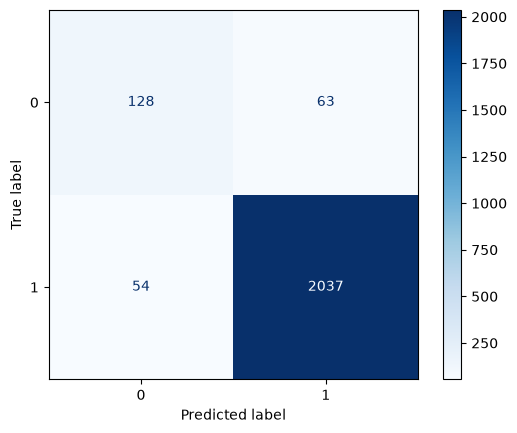

In [19]:
prediction_paid_male, prediction_final_male, true_paid_male, true_income_male = make_prediction(
    models, train_test_values, feature_cols=feature_cols, sex_label='male', cls_threshold=0.70)

y_pred = prediction_paid_male.astype(float)
y_true = true_paid_male

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(cm)
disp.plot(cmap="Blues")

plt.show()

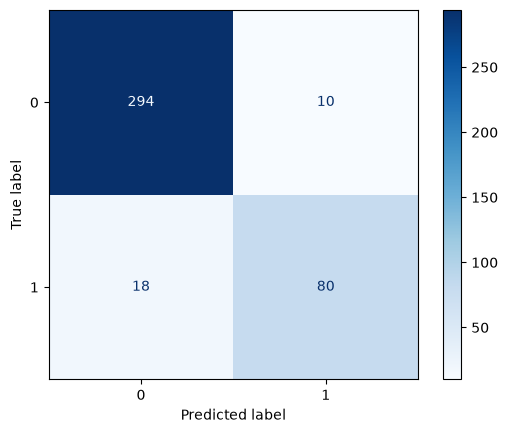

In [20]:
prediction_paid_female, prediction_final_female, true_paid_female, true_income_female = make_prediction(
    models, train_test_values, feature_cols=feature_cols, sex_label='female', cls_threshold=0.33)

y_pred = prediction_paid_female.astype(float)
y_true = true_paid_female

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(cm)
disp.plot(cmap="Blues")

plt.show()

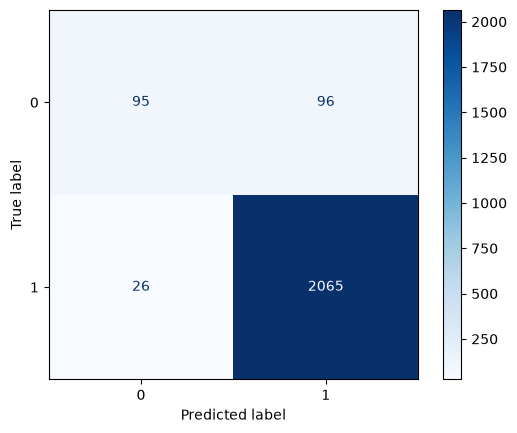

In [21]:
prediction_paid_male_nr, prediction_final_male_nr, _, _ = make_prediction(
    models_no_ribasim, train_test_values, feature_cols=feature_cols_nr, sex_label='male')

y_pred = prediction_paid_male_nr.astype(float)
y_true = true_paid_male

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(cm)
disp.plot(cmap="Blues")

plt.show()

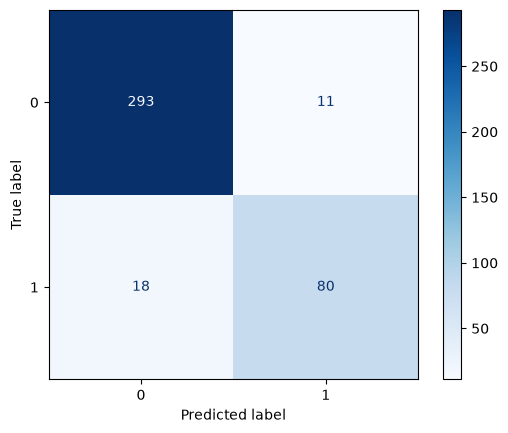

In [22]:
prediction_paid_female_nr, prediction_final_female_nr, _, _ = make_prediction(
    models_no_ribasim, train_test_values, feature_cols=feature_cols_nr, sex_label='female', cls_threshold=0.33)

y_pred = prediction_paid_female_nr.astype(float)
y_true = true_paid_female

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(cm)
disp.plot(cmap="Blues")

plt.show()

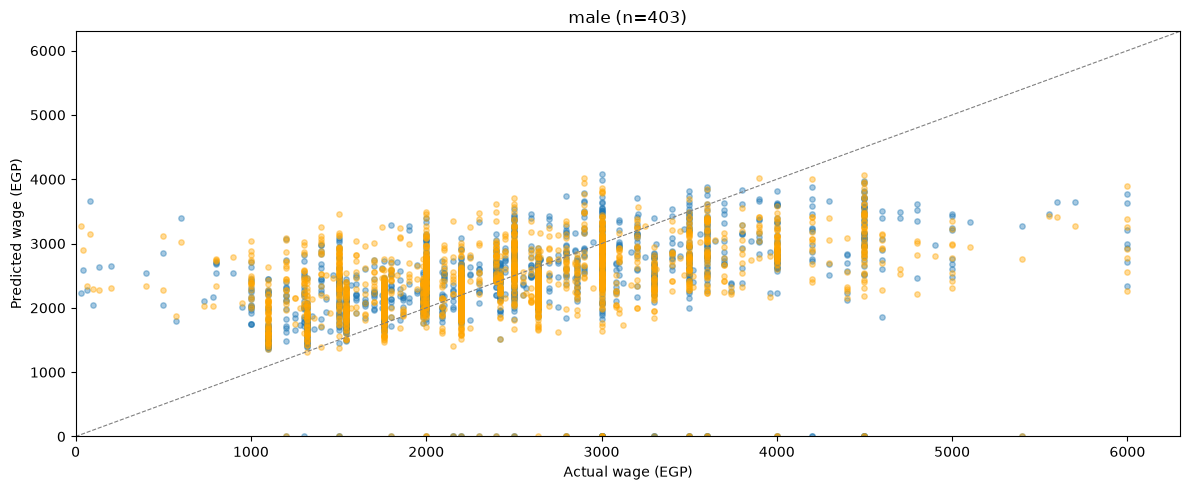

{'n': 2112, 'mae': 525.952839011386, 'r2': 0.15993420190298302, 'spearman': np.float64(0.6240436786273799)}


In [20]:
fig, ax = plt.subplots(figsize=(12, 5))
y_pred_male = prediction_final_male
y_true_male = true_income_male
y_pred_nr_male = prediction_final_male_nr

y_pred_male = y_pred_male[y_true_male > 0]
y_pred_nr_male = y_pred_nr_male[y_true_male > 0]
y_true_male = y_true_male[y_true_male > 0]

ax.scatter(y_true_male, y_pred_male, alpha=0.4, s=15)
ax.scatter(y_true_male, y_pred_nr_male, alpha=0.4, s=15, color='orange')
lims = [0.95 * min(y_true_male.min(), y_pred_male.min()), max(y_true_male.max(), y_pred_male.max()) * 1.05]
ax.plot(lims, lims, color="gray", linestyle="--", linewidth=0.8)
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("Actual wage (EGP)")
ax.set_title(f"male (n={len(y_true)})")
ax.set_ylabel("Predicted wage (EGP)")
plt.tight_layout()
plt.show()

metrics = {
    "n": len(y_true_male),
    "mae": mean_absolute_error(y_true_male, y_pred_male),
    "r2": r2_score(y_true_male, y_pred_male),
    "spearman": sstats.spearmanr(y_true_male, y_pred_male).correlation,
}
print(metrics)

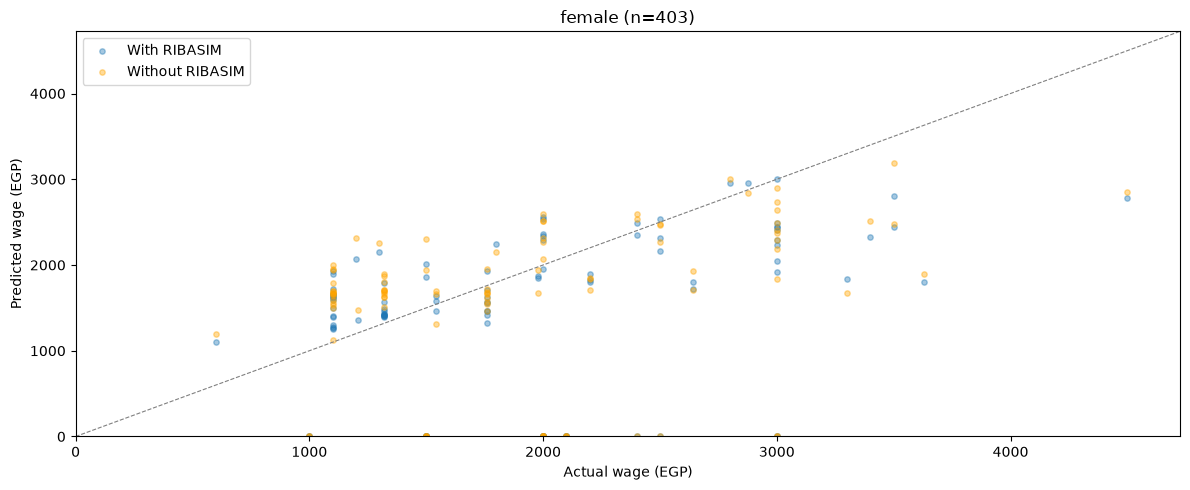

{'n': 99, 'mae': 704.5803262711131, 'r2': -0.7282365590891435, 'spearman': np.float64(0.45530223586230795)}
{'n': 99, 'mae': 743.7053996919997, 'r2': -0.7759129698708287, 'spearman': np.float64(0.4108343187199338)}


In [21]:
fig, ax = plt.subplots(figsize=(12, 5))
y_pred_female = prediction_final_female
y_pred_nr_female = prediction_final_female_nr
y_true_female = true_income_female

y_pred_female = y_pred_female[y_true_female > 0]
y_pred_nr_female = y_pred_nr_female[y_true_female > 0]
y_true_female = y_true_female[y_true_female > 0]

ax.scatter(y_true_female, y_pred_female, alpha=0.4, s=15, label='With RIBASIM')
ax.scatter(y_true_female, y_pred_nr_female, alpha=0.4, s=15, color='orange', label='Without RIBASIM')
lims = [0.95 * min(y_true_female.min(), y_pred_female.min()), max(y_true_female.max(), y_pred_female.max()) * 1.05]
ax.plot(lims, lims, color="gray", linestyle="--", linewidth=0.8)
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("Actual wage (EGP)")
ax.set_title(f"female (n={len(y_true)})")
ax.set_ylabel("Predicted wage (EGP)")
ax.legend()
plt.tight_layout()
plt.show()

metrics = {
    "n": len(y_true_female),
    "mae": mean_absolute_error(y_true_female, y_pred_female),
    "r2": r2_score(y_true_female, y_pred_female),
    "spearman": sstats.spearmanr(y_true_female, y_pred_female).correlation,
}
metrics_nr = {
    "n": len(y_true_female),
    "mae": mean_absolute_error(y_true_female, y_pred_nr_female),
    "r2": r2_score(y_true_female, y_pred_nr_female),
    "spearman": sstats.spearmanr(y_true_female, y_pred_nr_female).correlation,
}
print(metrics)
print(metrics_nr)

In [27]:
y_pred_female.mean() # 'baseline'

np.float64(1526.015994709469)

In [26]:
y_pred_female.mean() # 50

np.float64(1585.6341741984443)

In [21]:
y_pred_female.mean() # 70

np.float64(1554.7125714745562)

In [23]:
y_pred_male.mean() # 80

np.float64(2389.644784181034)

In [27]:
y_true_female.mean()

np.float32(1934.697)

In [24]:
plt.scatter(
    y_pred_nr[y_true > 0],
    y_pred[y_true > 0],
    alpha=0.5
)

plt.plot([0, 5000], [0, 5000], "--")
plt.xlabel("Prediction without RIBASIM")
plt.ylabel("Prediction with RIBASIM")


NameError: name 'y_pred_nr' is not defined

In [25]:
error_with = np.abs(y_true[y_true > 0] - y_pred[y_true > 0])
error_without = np.abs(y_true[y_true > 0] - y_pred_nr[y_true > 0])

plt.boxplot([error_with, error_without])
plt.ylabel("Absolute error (EGP)")

NameError: name 'y_pred_nr' is not defined

Text(0.5, 0, 'Reduction in absolute error (EGP)')

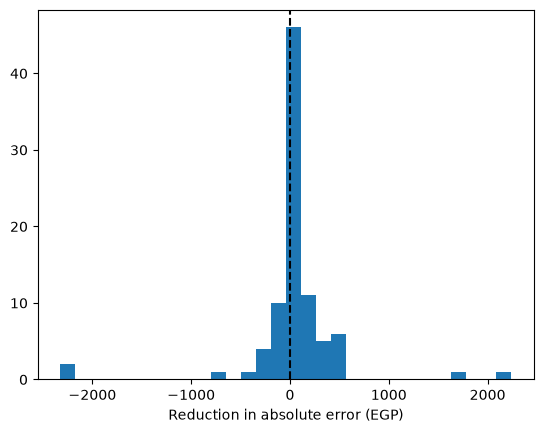

In [25]:
improvement = (
    np.abs(y_true[y_true > 0] - y_pred_nr[y_true > 0])
    - np.abs(y_true[y_true > 0] - y_pred[y_true > 0])
)

plt.hist(improvement, bins=30)
plt.axvline(0, color="k", ls="--")
plt.xlabel("Reduction in absolute error (EGP)")

{'whiskers': [<matplotlib.lines.Line2D at 0x33e72d700>,
 'caps': [<matplotlib.lines.Line2D at 0x33e72dca0>,
 'boxes': [<matplotlib.lines.Line2D at 0x33e72d490>,
 'medians': [<matplotlib.lines.Line2D at 0x177f2b890>,
 'fliers': [<matplotlib.lines.Line2D at 0x177f40bc0>,
 'means': [<matplotlib.lines.Line2D at 0x177f42c60>,
  <matplotlib.lines.Line2D at 0x33e4594f0>]}

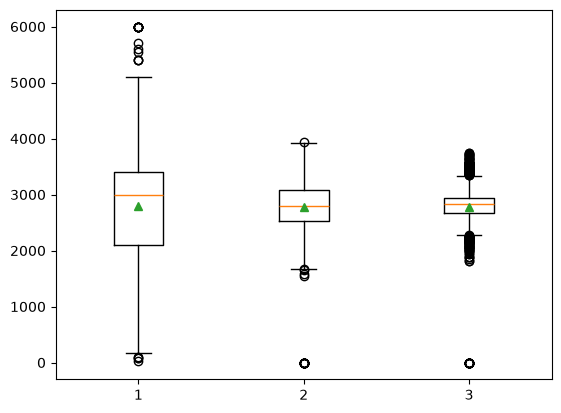

In [31]:
plt.boxplot([y_true, y_pred, y_pred_nr], showmeans=True)
# plt.boxplot(final_income, showmeans=True)

In [25]:
feature_cols

['age',
 'sex',
 'mart_d',
 'rel',
 'immigr',
 'disabl',
 'lit',
 'attsch',
 'yeduc',
 'tenure',
 'empstab',
 'hlthins',
 'socsec',
 'household_size',
 'n_other_employed',
 'water_productivity',
 'surface_water_mean',
 'ground_water_mean',
 'supply_demand_ratio',
 'water_supply',
 'water_demand',
 'gdp_pc',
 'rwi_mean',
 'cattle',
 'chicken',
 'goats',
 'sheeps',
 'producer_price',
 'occ']

In [60]:
FIGURE_DIR = REPO_ROOT / 'figures'
FIGURE_DIR.mkdir(exist_ok=True)

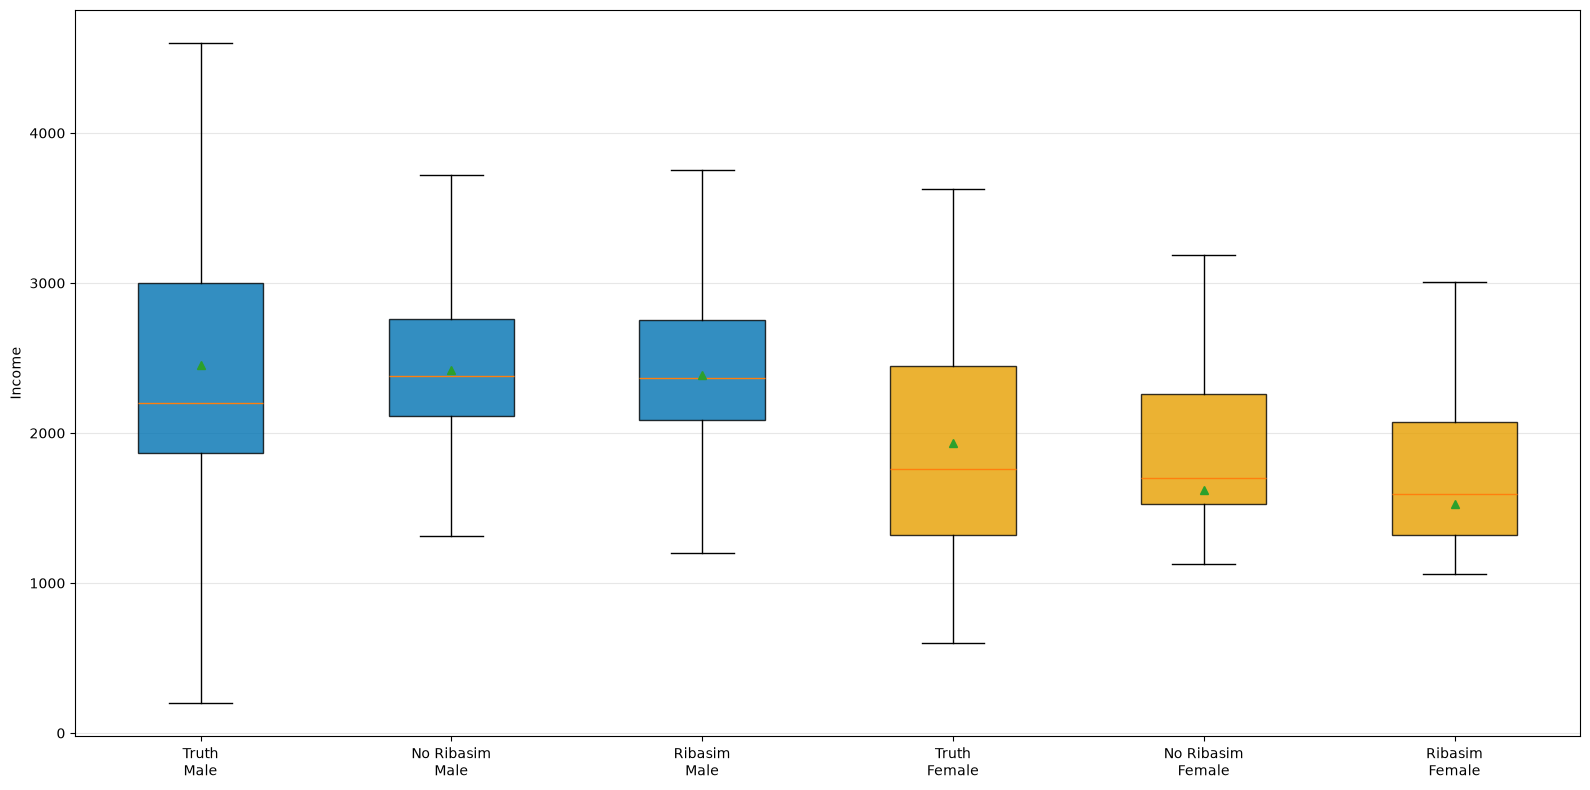

<Figure size 640x480 with 0 Axes>

In [65]:
y_pred_male = prediction_final_male
y_true_male = true_income_male
y_pred_nr_male = prediction_final_male_nr

y_pred_male = y_pred_male[y_true_male > 0]
y_pred_nr_male = y_pred_nr_male[y_true_male > 0]
y_true_male = y_true_male[y_true_male > 0]

y_pred_female = prediction_final_female
y_pred_nr_female = prediction_final_female_nr
y_true_female = true_income_female

y_pred_female = y_pred_female[y_true_female > 0]
y_pred_nr_female = y_pred_nr_female[y_true_female > 0]
y_true_female = y_true_female[y_true_female > 0]

fig, ax = plt.subplots(figsize=(16, 8))

data = [
    y_true_male,
    y_pred_nr_male,
    y_pred_male,
    y_true_female,
    y_pred_nr_female,
    y_pred_female,
]

labels = [
    "Truth\nMale",
    "No Ribasim\nMale",
    "Ribasim\nMale",
    "Truth\nFemale",
    "No Ribasim\nFemale",
    "Ribasim\nFemale",
]

bp = ax.boxplot(
    data,
    patch_artist=True,
    showmeans=True,
    showfliers=False,
)

colors = [
    "#0072B2", "#0072B2",
    "#0072B2", "#E69F00",
    "#E69F00", "#E69F00",
]

for box, color in zip(bp["boxes"], colors):
    box.set_facecolor(color)
    box.set_alpha(0.8)

ax.set_xticklabels(labels)

ax.set_ylabel("Income")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()
plt.savefig(FIGURE_DIR / 'baseline-box-plots-with-hrs-22.png')

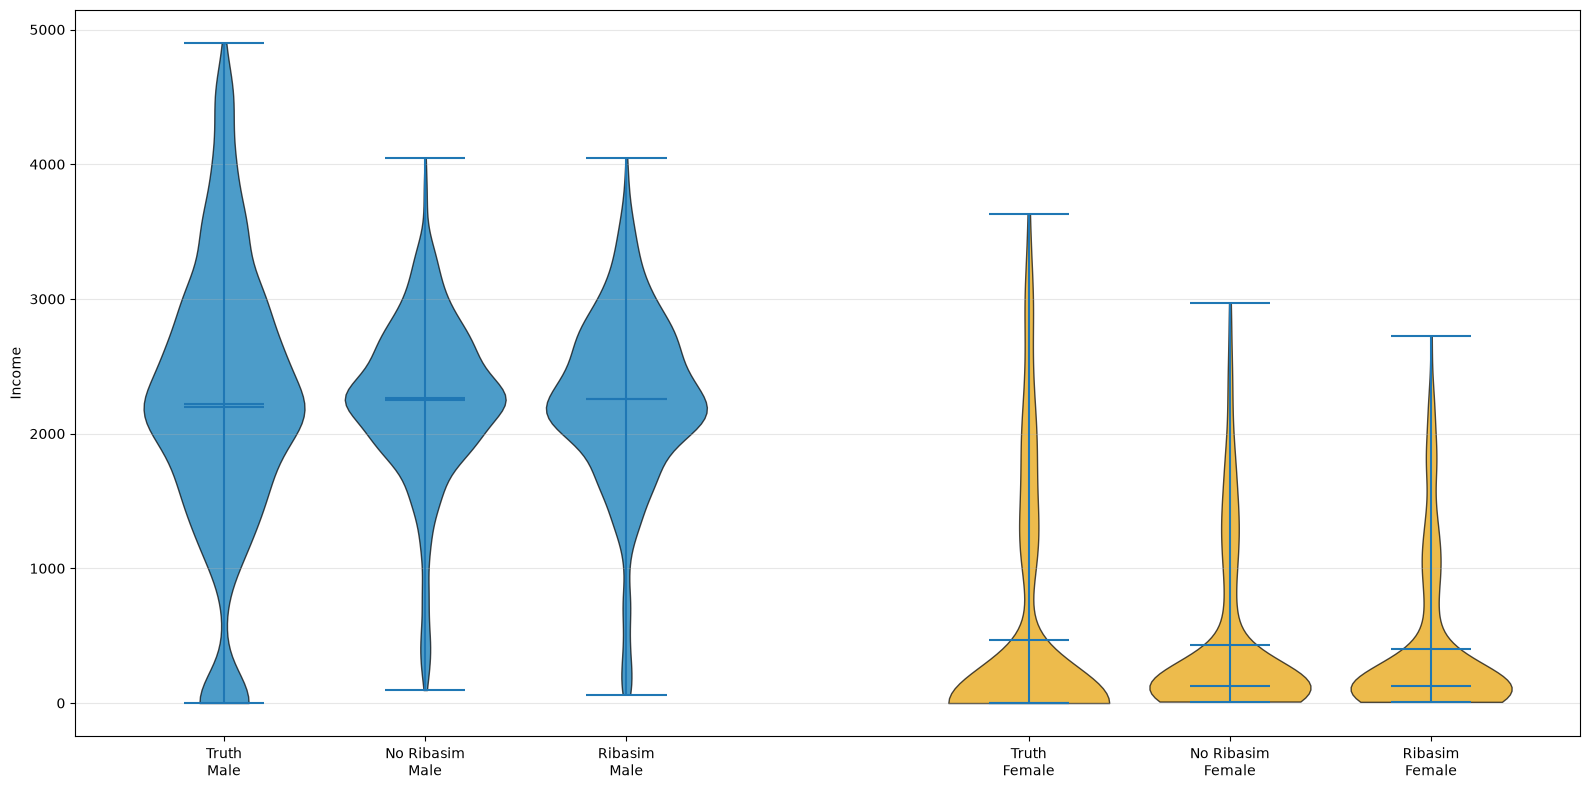

In [23]:
y_pred_male = prediction_final_male
y_true_male = true_income_male
y_pred_nr_male = prediction_final_male_nr

y_pred_female = prediction_final_female
y_pred_nr_female = prediction_final_female_nr
y_true_female = true_income_female

fig, ax = plt.subplots(figsize=(16, 8))

data = [
    y_true_male,
    y_pred_nr_male,
    y_pred_male,
    y_true_female,
    y_pred_nr_female,
    y_pred_female,
]

positions = [1, 2, 3, 5, 6, 7]

vp = ax.violinplot(
    data,
    positions=positions,
    widths=0.8,
    showmeans=True,
    showmedians=True,
)

colors = [
    "#0072B2", "#0072B2",  # Truth
    "#0072B2", "#E69F00",  # Ribasim
    "#E69F00", "#E69F00",  # No Ribasim
]

for body, color in zip(vp["bodies"], colors):
    body.set_facecolor(color)
    body.set_edgecolor("black")
    body.set_alpha(0.7)

ax.set_xticks(positions)
ax.set_xticklabels([
    "Truth\nMale",
    "No Ribasim\nMale",
    "Ribasim\nMale",
    "Truth\nFemale",
    "No Ribasim\nFemale",
    "Ribasim\nFemale",
])

ax.set_ylabel("Income")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
# plt.show()
# plt.savefig(FIGURE_DIR / 'baseline-violin-plots-with-hrs-22.png')